# 03 — Evaluación walk-forward de correctores TSMOM

> La pregunta es si los correctores aprendidos sobre TSMOM conservan utilidad económica al reentrenarse cronológicamente. Se usan tres evaluaciones sucesivas de XLE; los resultados son exploratorios porque XLE y las configuraciones ya han sido estudiados.

## <b>Block 01 — Datos, baseline y cronología</b>

> Se conserva el baseline de las notebooks 01 y 02: momentum logarítmico de 126 sesiones, volatilidad EWMA $\lambda=0.94$, objetivo anual de 12%, tope 1 y decisión al cierre de $t$ aplicada al retorno de $t+1$. Gold local es la única fuente.

In [1]:
from pathlib import Path
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import torch
from torch import nn
torch.set_num_threads(1)

SEED, EPOCHS, LEARNING_RATE = 42, 80, 0.01
START = pd.Timestamp('2018-01-02')
MOMENTUM_FEATURES = (21, 63, 126)
EWMA_LAMBDA, EWMA_WARMUP = 0.94, 20
TARGET_VOLATILITY, MAX_EXPOSURE = 0.12, 1.00
LOOKBACK, ADJUSTMENT_LIMIT = 63, 0.20
RESEARCH_COST_PER_TURNOVER = 0.0005  # 5 bps por unidad; supuesto de investigación.
CYCLES = [
    ('2024', pd.Timestamp('2023-12-31'), pd.Timestamp('2024-01-01'), pd.Timestamp('2024-12-31')),
    ('2025', pd.Timestamp('2024-12-31'), pd.Timestamp('2025-01-01'), pd.Timestamp('2025-12-31')),
    ('2026', pd.Timestamp('2025-12-31'), pd.Timestamp('2026-01-01'), None),
]

def find_repo_root(start=Path.cwd()):
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'Momentum_systematic_strategies').is_dir():
            return candidate
    raise FileNotFoundError('No se encontró la raíz del repositorio.')

ROOT = find_repo_root()
GOLD_PATH = ROOT / 'Momentum_systematic_strategies' / 'data' / 'gold' / 'daily_series' / 'etf' / 'XLE.parquet'
gold = pl.read_parquet(GOLD_PATH).select('session_date', 'adjusted_close').sort('session_date')
GOLD_END = pd.Timestamp(gold.get_column('session_date').max())
print('Gold XLE: {} → {}'.format(gold.get_column('session_date').min(), GOLD_END.date()))

frame = pd.DataFrame(gold.filter(pl.col('session_date') >= START.date()).to_dict(as_series=False)).rename(columns={'session_date': 'decision_date'})
frame['decision_date'] = pd.to_datetime(frame['decision_date'])
frame['ret_1d'] = frame['adjusted_close'].pct_change()
for horizon in MOMENTUM_FEATURES:
    frame['mom_{}'.format(horizon)] = np.log(frame['adjusted_close'] / frame['adjusted_close'].shift(horizon))

ret = frame['ret_1d'].to_numpy(float)
variance = np.full(len(frame), np.nan)
first_valid = np.flatnonzero(np.isfinite(ret))[0]
initial_index = first_valid + EWMA_WARMUP - 1
variance[initial_index] = np.mean(ret[first_valid:initial_index + 1] ** 2)
for i in range(initial_index + 1, len(frame)):
    variance[i] = EWMA_LAMBDA * variance[i - 1] + (1 - EWMA_LAMBDA) * ret[i] ** 2
frame['ewma_vol_annual'] = np.sqrt(variance) * math.sqrt(252)
frame['baseline_position'] = np.where(frame['mom_126'] > 0, np.minimum(MAX_EXPOSURE, TARGET_VOLATILITY / frame['ewma_vol_annual']), 0.0)
frame['return_date'] = frame['decision_date'].shift(-1)
frame['next_return'] = frame['ret_1d'].shift(-1)
feature_columns = ['ret_1d', 'mom_21', 'mom_63', 'mom_126', 'ewma_vol_annual']
frame['ready'] = frame[feature_columns].notna().all(axis=1).astype(int).rolling(LOOKBACK).sum().eq(LOOKBACK)
frame['_row'] = np.arange(len(frame))
sample = frame.loc[frame['ready'] & frame['next_return'].notna()].copy().reset_index(drop=True)
assert (sample['return_date'] > sample['decision_date']).all()
assert sample['baseline_position'].between(0, 1).all()
print('Muestra causal: {} → {}; {:,} decisiones'.format(sample.decision_date.min().date(), sample.return_date.max().date(), len(sample)))

Gold XLE: 2018-01-02 → 2026-11-17
Muestra causal: 2018-10-01 → 2026-11-17; 2,043 decisiones


## <b>Block 02 — Correctores congelados</b>

> En cada ciclo se reinicializan con semilla 42 una LSTM de 8 unidades y ventana 63, una red feedforward de 8 unidades que ve solo las cinco variables actuales y un desplazamiento constante. Todas parten de corrección cero, entrenan 80 épocas y maximizan el mismo Sharpe neto.

In [2]:
class AnchoredLSTM(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.lstm = nn.LSTM(n_features, 8, num_layers=1, batch_first=True)
        self.residual = nn.Linear(8, 1)
        nn.init.zeros_(self.residual.weight); nn.init.zeros_(self.residual.bias)
    def forward(self, x):
        hidden, _ = self.lstm(x)
        return ADJUSTMENT_LIMIT * torch.tanh(self.residual(hidden[:, -1, :]).squeeze(-1))

class AnchoredFeedForward(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.hidden, self.residual = nn.Linear(n_features, 8), nn.Linear(8, 1)
        nn.init.zeros_(self.residual.weight); nn.init.zeros_(self.residual.bias)
    def forward(self, x):
        return ADJUSTMENT_LIMIT * torch.tanh(self.residual(torch.tanh(self.hidden(x))).squeeze(-1))

class ConstantCorrection(nn.Module):
    def __init__(self):
        super().__init__(); self.raw_adjustment = nn.Parameter(torch.zeros(()))
    def forward(self, x):
        return ADJUSTMENT_LIMIT * torch.tanh(self.raw_adjustment).expand(x.shape[0])

def train_model(model, inputs, train_idx, baseline_tensor, returns_tensor):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    index = torch.tensor(train_idx, dtype=torch.long)
    for _ in range(EPOCHS):
        optimizer.zero_grad()
        position = torch.clamp(baseline_tensor[index] + model(inputs[index]), 0.0, 1.0)
        turnover = torch.cat(((position[1:2] - position[:1]).abs(), (position[2:] - position[1:-1]).abs()))
        net = position[1:] * returns_tensor[index][1:] - RESEARCH_COST_PER_TURNOVER * turnover
        loss = -(net.mean() / net.std(unbiased=False).clamp_min(1e-6) * math.sqrt(252))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
    return model

def parameter_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

parameter_table = pd.DataFrame({
    'estrategia': ['TSMOM baseline', 'Corrección constante', 'Feedforward actual', 'LSTM 63 sesiones'],
    'parámetros entrenables': [0, parameter_count(ConstantCorrection()), parameter_count(AnchoredFeedForward(5)), parameter_count(AnchoredLSTM(5))],
})
parameter_table

,estrategia,parámetros entrenables
0,TSMOM baseline,0
1,Corrección constante,1
2,Feedforward actual,57
3,LSTM 63 sesiones,489


## <b>Block 03 — Reentrenamiento walk-forward</b>

> Un modelo queda disponible después del último retorno incluido en su entrenamiento. Sus decisiones de evaluación comienzan después de esa fecha y usan solo contexto histórico. Al cambiar de ciclo, la primera operación cobra el turnover contra la última posición evaluada del ciclo anterior; al inicio de 2024, se parte de efectivo.

In [3]:
daily_parts, cycle_rows, causal_rows = [], [], []
previous_position = {label: 0.0 for label in ['TSMOM baseline', 'Corrección constante', 'Feedforward actual', 'LSTM 63 sesiones']}

for cycle, train_end, evaluation_start, evaluation_end in CYCLES:
    evaluation_end = GOLD_END if evaluation_end is None else min(evaluation_end, GOLD_END)
    train_idx = np.flatnonzero((sample['return_date'] <= train_end).to_numpy())
    available_date = sample.loc[train_idx, 'return_date'].max()
    eval_idx = np.flatnonzero(((sample['return_date'] >= evaluation_start) & (sample['return_date'] <= evaluation_end) & (sample['decision_date'] > available_date)).to_numpy())
    assert len(train_idx) and len(eval_idx)
    assert sample.loc[eval_idx, 'decision_date'].min() > available_date

    train_rows = sample.loc[train_idx, '_row'].to_numpy()
    raw = frame[feature_columns].to_numpy(dtype=np.float32)
    mean, std = raw[train_rows].mean(0), np.maximum(raw[train_rows].std(0), 1e-8)
    scaled = (raw - mean) / std
    rows = sample['_row'].to_numpy()
    sequence = np.stack([scaled[row - LOOKBACK + 1:row + 1] for row in rows]).astype(np.float32)
    current = scaled[rows].astype(np.float32)
    assert np.array_equal(sequence[:, -1, :], current)

    seq_t, cur_t = torch.tensor(sequence), torch.tensor(current)
    base_t = torch.tensor(sample['baseline_position'].to_numpy(dtype=np.float32))
    ret_t = torch.tensor(sample['next_return'].to_numpy(dtype=np.float32))
    np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
    lstm = train_model(AnchoredLSTM(5), seq_t, train_idx, base_t, ret_t)
    feedforward = train_model(AnchoredFeedForward(5), cur_t, train_idx, base_t, ret_t)
    constant = train_model(ConstantCorrection(), cur_t, train_idx, base_t, ret_t)
    with torch.no_grad():
        all_positions = {
            'TSMOM baseline': sample['baseline_position'].to_numpy(),
            'Corrección constante': np.clip(sample['baseline_position'].to_numpy() + constant(cur_t).numpy(), 0, 1),
            'Feedforward actual': np.clip(sample['baseline_position'].to_numpy() + feedforward(cur_t).numpy(), 0, 1),
            'LSTM 63 sesiones': np.clip(sample['baseline_position'].to_numpy() + lstm(seq_t).numpy(), 0, 1),
        }
    dates = sample.loc[eval_idx, 'return_date'].to_numpy()
    realized = sample.loc[eval_idx, 'next_return'].to_numpy()
    for label, position in all_positions.items():
        weights = position[eval_idx]
        turnover = np.r_[abs(weights[0] - previous_position[label]), abs(np.diff(weights))]
        costs, gross = RESEARCH_COST_PER_TURNOVER * turnover, weights * realized
        net = gross - costs
        daily_parts.append(pd.DataFrame({'cycle': cycle, 'return_date': dates, 'estrategia': label, 'position': weights, 'gross': gross, 'costs': costs, 'net': net, 'turnover': turnover}))
        previous_position[label] = weights[-1]
    causal_rows.append({'ciclo': cycle, 'modelo disponible tras': available_date.date(), 'primera decisión': sample.loc[eval_idx, 'decision_date'].min().date(), 'primer retorno evaluado': pd.Timestamp(dates[0]).date(), 'retornos': len(eval_idx)})

daily = pd.concat(daily_parts, ignore_index=True)
causal_schedule = pd.DataFrame(causal_rows)
assert daily.groupby('estrategia').size().nunique() == 1
assert daily.groupby('estrategia')['return_date'].apply(tuple).nunique() == 1
causal_schedule

,ciclo,modelo disponible tras,primera decisión,primer retorno evaluado,retornos
0,2024,2023-12-29,2024-01-02,2024-01-03,251
1,2025,2024-12-31,2025-01-02,2025-01-03,249
2,2026,2025-12-31,2026-01-02,2026-01-05,220


## <b>Block 04 — Resultados por año y trayectoria concatenada</b>

> Todas las estrategias comparten las mismas fechas dentro de cada ciclo. El retorno neto compuesto se calcula sobre el NAV concatenado; los costes de frontera ya están incorporados en el primer retorno de cada ciclo.

,cycle,estrategia,retorno neto compuesto (%),volatilidad anual (%),Sharpe neto,max drawdown (%),exposición media (%),turnover total,costes totales (%)
0,2024,TSMOM baseline,-13.280,9.969,-1.385,-14.197,46.020,14.033,0.702
1,2024,Corrección constante,-12.611,11.555,-1.113,-15.204,57.452,13.866,0.693
2,2024,Feedforward actual,-9.559,7.357,-1.334,-10.559,33.754,11.145,0.557
3,2024,LSTM 63 sesiones,-9.486,7.282,-1.337,-10.404,33.253,10.850,0.542
4,2025,TSMOM baseline,-5.633,10.528,-0.504,-11.819,37.284,16.170,0.809
5,2025,Corrección constante,-4.794,12.645,-0.329,-12.468,49.251,16.174,0.809
6,2025,Feedforward actual,-5.359,8.437,-0.618,-9.864,30.279,14.753,0.738
7,2025,LSTM 63 sesiones,-2.206,9.930,-0.177,-8.840,41.250,22.390,1.119
8,2026,TSMOM baseline,22.854,12.713,1.919,-8.276,52.414,3.672,0.184
9,2026,Corrección constante,28.021,15.563,1.897,-10.059,64.429,3.671,0.184


,estrategia,retorno neto compuesto (%),volatilidad anual (%),Sharpe neto,max drawdown (%),exposición media (%),turnover total,costes totales (%),Δ neto diario medio vs TSMOM (bps),Δ neto suma vs TSMOM (%)
0,TSMOM baseline,0.538,11.108,0.073,-22.057,44.952,33.875,1.694,0.000,0.000
1,Corrección constante,6.512,13.309,0.233,-22.470,56.748,33.712,1.686,0.909,6.545
2,Feedforward actual,0.975,8.695,0.083,-17.579,35.066,34.159,1.708,-0.035,-0.252
3,LSTM 63 sesiones,7.901,9.225,0.335,-15.270,37.441,46.032,2.302,0.905,6.516


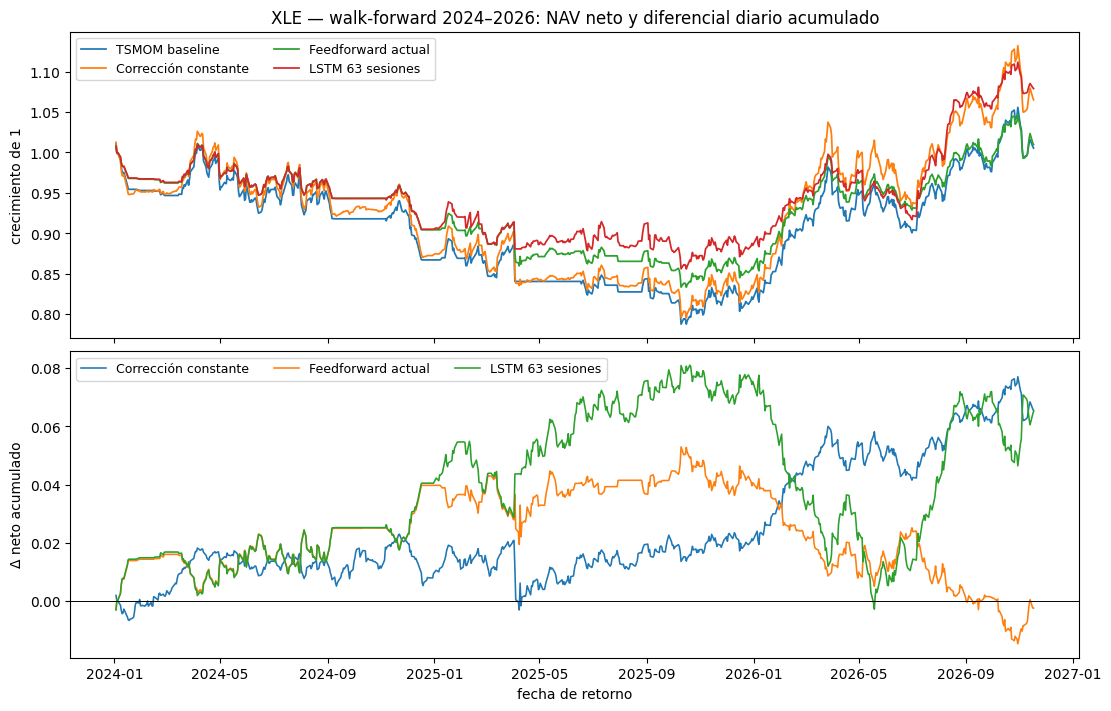

In [4]:
def metrics_for(part):
    net = part['net'].to_numpy(); nav = np.r_[1.0, np.cumprod(1 + net)]
    vol = net.std(ddof=0) * math.sqrt(252)
    return pd.Series({
        'retorno neto compuesto (%)': (nav[-1] - 1) * 100,
        'volatilidad anual (%)': vol * 100,
        'Sharpe neto': net.mean() / max(net.std(ddof=0), 1e-8) * math.sqrt(252),
        'max drawdown (%)': (nav / np.maximum.accumulate(nav) - 1).min() * 100,
        'exposición media (%)': part['position'].mean() * 100,
        'turnover total': part['turnover'].sum(),
        'costes totales (%)': part['costs'].sum() * 100,
    })

yearly = daily.groupby(['cycle', 'estrategia'], sort=False).apply(metrics_for, include_groups=False).reset_index()
combined = daily.groupby('estrategia', sort=False).apply(metrics_for, include_groups=False).reset_index()
baseline_net = daily.loc[daily['estrategia'] == 'TSMOM baseline', ['return_date', 'net']].set_index('return_date')['net']
daily_delta = daily.join(baseline_net.rename('baseline_net'), on='return_date')
delta_summary = daily_delta.groupby('estrategia', sort=False).apply(lambda x: pd.Series({'Δ neto diario medio vs TSMOM (bps)': (x['net'] - x['baseline_net']).mean() * 1e4, 'Δ neto suma vs TSMOM (%)': (x['net'] - x['baseline_net']).sum() * 100}), include_groups=False).reset_index()
combined = combined.merge(delta_summary, on='estrategia')
display(yearly.round(3))
display(combined.round(3))

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, layout='constrained')
for label, part in daily.groupby('estrategia', sort=False):
    part = part.sort_values('return_date'); nav = np.cumprod(1 + part['net'].to_numpy())
    axes[0].plot(part['return_date'], nav, label=label, lw=1.25)
    if label != 'TSMOM baseline':
        axes[1].plot(part['return_date'], np.cumsum(part['net'].to_numpy() - baseline_net.loc[part['return_date']].to_numpy()), label=label, lw=1.15)
axes[0].set_title('XLE — walk-forward 2024–2026: NAV neto y diferencial diario acumulado')
axes[0].set_ylabel('crecimiento de 1'); axes[0].legend(ncol=2, fontsize=9)
axes[1].axhline(0, color='black', lw=0.7); axes[1].set_ylabel('Δ neto acumulado'); axes[1].set_xlabel('fecha de retorno'); axes[1].legend(ncol=3, fontsize=9)
plt.show()

## <b>Conclusión</b>

- Cada observación de evaluación procede de un modelo reentrenado solo con retornos anteriores a su fecha de disponibilidad.
- La comparación por ciclos y la trayectoria concatenada describen estabilidad temporal, no seleccionan retrospectivamente una estrategia ganadora.
- La selección previa de XLE y la exploración de notebooks anteriores limitan la independencia de cualquier resultado favorable.
- Los costes son un supuesto de investigación y esta simulación de retornos diarios no representa ejecución con órdenes y fills.